# Advanced EDA & Feature Engineering — E-commerce Orders

**DecodeLabs Data Science Internship · Project 1**



## 1. Setup

Import the libraries and the project package. The first lines locate the project root,
so the notebook works no matter which folder Jupyter / VS Code was started from.

In [1]:
import sys
from pathlib import Path

# Find the project root (the folder that contains feature_pipeline/) and make it importable
ROOT = Path.cwd()
while not (ROOT / "feature_pipeline").exists() and ROOT != ROOT.parent:
    ROOT = ROOT.parent
sys.path.insert(0, str(ROOT))

import logging
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display

from feature_pipeline import FeaturePipeline, config, report
from feature_pipeline.missing import missing_report, run_imputation_experiment
from feature_pipeline.outliers import outlier_summary
from feature_pipeline.schema import raw_schema

logging.basicConfig(level=logging.INFO, format="%(levelname)s | %(message)s", stream=sys.stdout, force=True)
pd.set_option("display.max_columns", 40)
pd.set_option("display.width", 200)
print("Project root:", ROOT.name)
print("pandas", pd.__version__, "| numpy", np.__version__)

Project root: ecommerce-eda-feature-engineering
pandas 3.1.1 | numpy 2.5.4


## 2. Load the data



In [2]:
raw = pd.read_excel(config.RAW_DATA_PATH)
print(f"Shape: {raw.shape[0]} rows x {raw.shape[1]} columns")
raw.head()

Shape: 1200 rows x 14 columns


,OrderID,Date,CustomerID,Product,Quantity,UnitPrice,ShippingAddress,PaymentMethod,OrderStatus,TrackingNumber,ItemsInCart,CouponCode,ReferralSource,TotalPrice
0,ORD200000,2023-01-04,C72649,Monitor,5,570.62,928 Main St,Debit Card,Shipped,TRK37947903,7,SAVE10,Instagram,2853.10
1,ORD200001,2024-08-23,C75739,Phone,2,151.35,823 Main St,Online,Shipped,TRK91186779,3,SAVE10,Referral,302.70
2,ORD200002,2024-02-27,C81728,Tablet,5,550.68,512 Main St,Credit Card,Cancelled,TRK42903982,8,FREESHIP,Email,2753.40
3,ORD200003,2023-10-15,C33540,Chair,1,273.19,275 Main St,Debit Card,Returned,TRK62788070,5,SAVE10,Facebook,273.19
4,ORD200004,2025-05-08,C81840,Printer,4,626.01,668 Main St,Online,Delivered,TRK29241424,8,SAVE10,Email,2504.04


### 2.1 Column types

Each row is one order. `Date` is already parsed as a date; prices are decimals; counts are integers.

In [3]:
raw.dtypes.to_frame("dtype")

,dtype
OrderID,str
Date,datetime64[us]
CustomerID,str
Product,str
Quantity,int64
UnitPrice,float64
ShippingAddress,str
PaymentMethod,str
OrderStatus,str
TrackingNumber,str


## 3. Data-quality checks

Before cleaning, confirm the data is trustworthy: no duplicate orders, and the two
business rules hold for every row:

1. `ItemsInCart >= Quantity` (the cart holds at least this product)
2. `TotalPrice == Quantity x UnitPrice`

In [4]:
checks = {
    "duplicate rows": int(raw.duplicated().sum()),
    "duplicate OrderID": int(raw["OrderID"].duplicated().sum()),
    "duplicate TrackingNumber": int(raw["TrackingNumber"].duplicated().sum()),
    "rows with ItemsInCart < Quantity": int((raw["ItemsInCart"] < raw["Quantity"]).sum()),
    "rows where TotalPrice != Quantity x UnitPrice": int(
        (~np.isclose(raw["TotalPrice"], raw["Quantity"] * raw["UnitPrice"], atol=config.PRICE_TOLERANCE)).sum()
    ),
}
pd.Series(checks, name="count").to_frame()

,count
duplicate rows,0
duplicate OrderID,0
duplicate TrackingNumber,0
rows with ItemsInCart < Quantity,0
rows where TotalPrice != Quantity x UnitPrice,0


### 3.1 Identifier columns

Columns that are (almost) unique per order cannot teach a model a general pattern.
`ShippingAddress` is always `"<number> Main St"`, so the house number is noise.
These three columns are dropped from the model table.

In [5]:
id_check = pd.DataFrame({
    "unique_values": raw[config.IDENTIFIER_COLUMNS_TO_DROP].nunique(),
    "rows": len(raw),
})
display(id_check)
print("Street names in ShippingAddress:",
      raw["ShippingAddress"].str.replace(r"^\d+\s+", "", regex=True).unique())

,unique_values,rows
CustomerID,1189,1200
TrackingNumber,1200,1200
ShippingAddress,655,1200


Street names in ShippingAddress: <ArrowStringArray>
['Main St']
Length: 1, dtype: str


### 3.2 Input contract (Pandera)

The same checks are written as a formal data contract in `feature_pipeline/schema.py`.


In [6]:
validated = raw_schema.validate(raw.copy(), lazy=True)
print("Input contract passed for all", len(validated), "rows.")

Input contract passed for all 1200 rows.


## 4. Exploratory data analysis

### 4.1 Numeric columns

In [7]:
raw[config.NUMERIC_COLUMNS].describe().T.round(2)

,count,mean,std,min,25%,50%,75%,max
Quantity,1200.0,2.95,1.41,1.00,2.00,3.00,4.00,5.00
UnitPrice,1200.0,356.41,197.18,11.39,186.06,364.21,521.57,699.93
ItemsInCart,1200.0,5.48,2.28,1.00,4.00,5.00,7.00,10.00
TotalPrice,1200.0,1053.97,819.86,11.39,410.52,823.62,1578.48,3456.40


#### Distribution of each numeric column

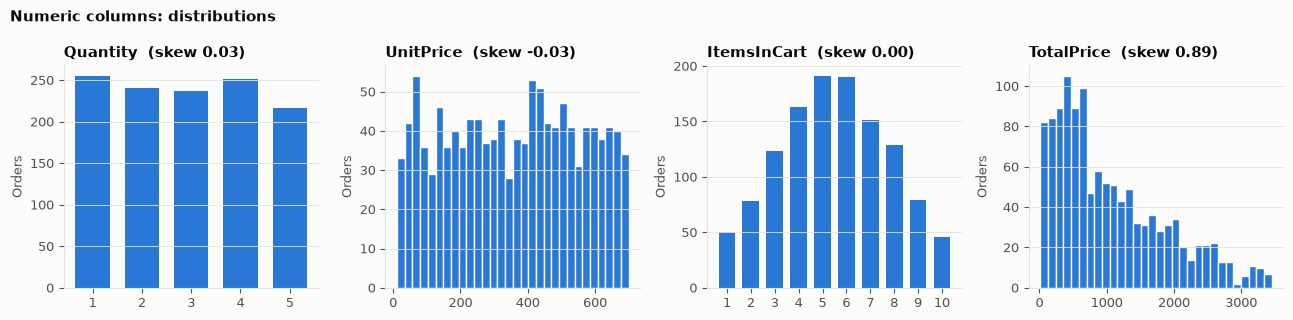

In [8]:
fig = report.plot_numeric_distributions(raw)
plt.show()

**Observations**

- `Quantity` (1–5) and `UnitPrice` (about 11–700) are spread almost evenly across their range (skew ≈ 0).
- `ItemsInCart` (1–10) is centred on 5–6.
- `TotalPrice` is right-skewed (skew ≈ 0.89): it is a product of two columns, so large
  quantities of expensive items create a long right tail.

### 4.2 Categorical columns

#### Order count per category

In [9]:
for col in config.CATEGORICAL_COLUMNS:
    print(f"{col:15s}", raw[col].fillna("(blank)").value_counts().to_dict())

Product         {'Printer': 181, 'Tablet': 179, 'Chair': 178, 'Laptop': 173, 'Desk': 170, 'Monitor': 163, 'Phone': 156}
PaymentMethod   {'Online': 258, 'Cash': 246, 'Credit Card': 234, 'Debit Card': 232, 'Gift Card': 230}
OrderStatus     {'Cancelled': 250, 'Returned': 247, 'Pending': 237, 'Shipped': 235, 'Delivered': 231}
CouponCode      {'FREESHIP': 313, '(blank)': 309, 'WINTER15': 292, 'SAVE10': 286}
ReferralSource  {'Instagram': 259, 'Email': 250, 'Google': 241, 'Facebook': 228, 'Referral': 222}


#### Category counts as charts

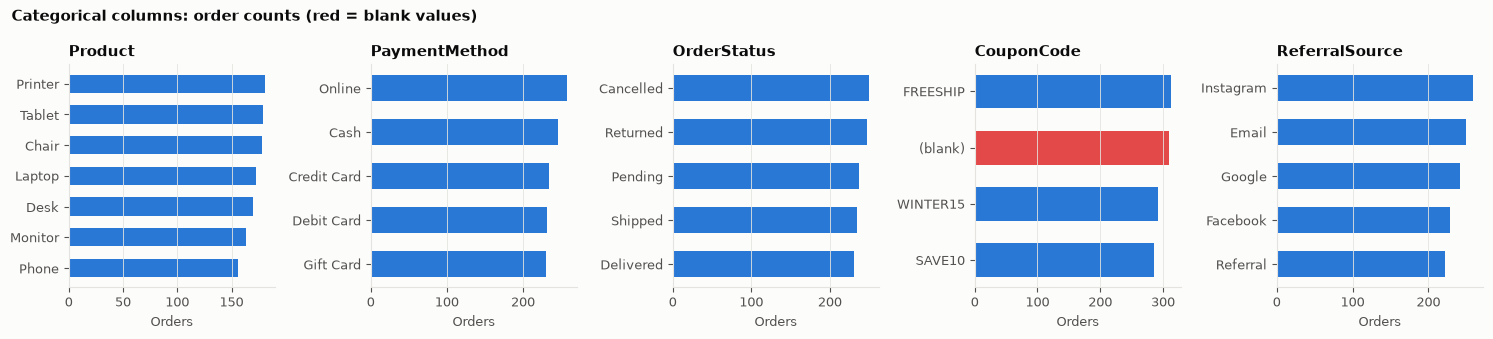

In [10]:
fig = report.plot_categorical_distributions(raw)
plt.show()

**Observations**

- Every category is well represented (roughly 150–310 orders each), so no category is too rare to encode.
- `CouponCode` is the only column with blanks (shown in red).
- The very even spread of every column, together with the identical street name, suggests this
  is a practice / synthetic dataset. The methods are the same as for real data.

### 4.3 Orders over time

In [11]:
orders_per_year = raw["Date"].dt.year.value_counts().sort_index()
print("Date range:", raw["Date"].min().date(), "to", raw["Date"].max().date())
orders_per_year.to_frame("orders")

Date range: 2023-01-01 to 2025-06-30


,orders
Date,
2023,510
2024,459
2025,231


2025 has fewer orders because the data ends on 30 June 2025 (half a year).

## 5. Phase 1 — Missing values and the decision matrix

The training kit's decision matrix:

| Missing | Action |
|---|---|
| < 5% | drop the affected rows |
| 5% – 20% | statistical imputation (median) |
| > 20% | multi-dimensional estimation (KNN) |

In [12]:
miss = missing_report(raw)
miss[miss["missing_pct"] > 0]

,missing_count,missing_pct,strategy
column,,,
CouponCode,309,25.75,structural_fill


#### Missing values across all columns

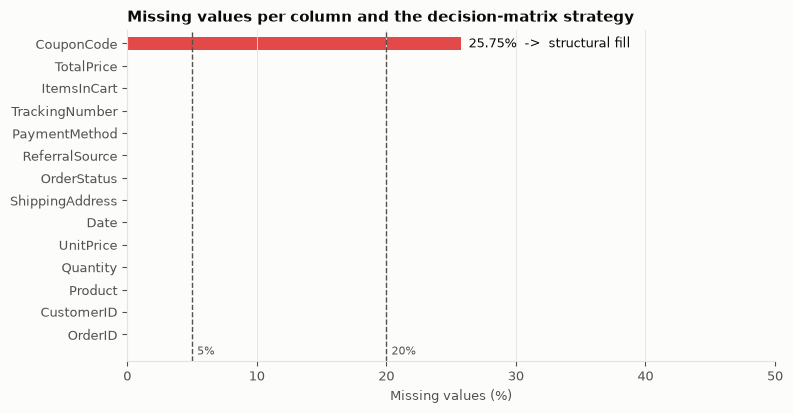

In [13]:
fig = report.plot_missing_values(miss)
plt.show()

### 5.1 Why `CouponCode` is not imputed with KNN

`CouponCode` is 25.75% blank, which the matrix would send to KNN. But a blank coupon
has a clear business meaning: **the customer did not use a coupon**. Estimating a coupon
from similar orders would invent discounts that never happened.

So the blank is replaced with the explicit label `"NONE"` and a 0/1 feature `HasCoupon`
is created.

The check below tests whether blank coupons are linked to any other column, which
would hint at a data-collection fault. A chi-square test of independence is run for
each categorical column; p > 0.05 means no significant link.

In [14]:
from scipy.stats import chi2_contingency

blank = raw["CouponCode"].isna().rename("CouponBlank")
rows = []
for col in ["OrderStatus", "Product", "PaymentMethod", "ReferralSource"]:
    table = pd.crosstab(raw[col], blank)
    share = (table[True] / table.sum(axis=1) * 100)
    rows.append({
        "column": col,
        "lowest % blank": round(share.min(), 1),
        "highest % blank": round(share.max(), 1),
        "chi-square p-value": round(chi2_contingency(table)[1], 3),
    })
independence = pd.DataFrame(rows).set_index("column")
independence["significant link?"] = np.where(independence["chi-square p-value"] < 0.05, "yes", "no")
independence

,lowest % blank,highest % blank,chi-square p-value,significant link?
column,,,,
OrderStatus,22.5,30.8,0.220,no
Product,23.2,28.8,0.928,no
PaymentMethod,21.3,31.0,0.124,no
ReferralSource,22.0,29.4,0.331,no


## 6. Imputation experiment — Mean vs Median vs KNN

This dataset has **no missing numeric values**, so to compare the methods honestly we
create missing values on purpose:

1. Hide 15% of `ItemsInCart` at random (inside the 5–20% band).
2. Fill the gaps with Mean, Median and KNN (k = 5, using Quantity, UnitPrice, TotalPrice).
3. Compare with the **true** hidden values. Repeat 20 times with different random gaps and average.

Metrics: **MAE / RMSE** (error on hidden values, lower is better), **std_after**
(spread after filling; closer to the true std is better) and **KS** (distance between the
filled and true distributions, lower is better).

In [15]:
experiment, example, truth = run_imputation_experiment(raw)
experiment

,MAE_on_hidden,RMSE_on_hidden,std_after,KS_vs_true
method,,,,
True values (reference),0.000,0.000,2.282,0.000
Mean,1.925,2.309,2.099,0.080
Median,1.950,2.379,2.106,0.079
KNN (k=5),1.640,1.914,2.197,0.025


### 6.1 Distribution after imputation (first repeat)

Blue bars = column after filling the gaps; black outline = the true values.

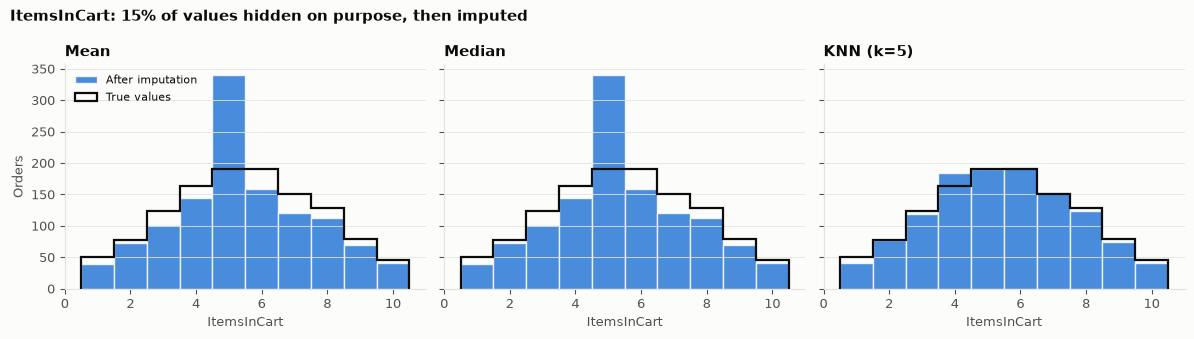

In [16]:
fig = report.plot_imputation_experiment(example, truth)
plt.show()

### 6.2 Which method has the lowest error?

In [17]:
best = experiment.drop(index="True values (reference)")["MAE_on_hidden"].idxmin()
mean_mae = experiment.loc["Mean", "MAE_on_hidden"]
best_mae = experiment.loc[best, "MAE_on_hidden"]
print(f"Lowest error: {best} (MAE {best_mae:.3f} vs {mean_mae:.3f} for Mean, "
      f"{(1 - best_mae / mean_mae) * 100:.1f}% lower)")

Lowest error: KNN (k=5) (MAE 1.640 vs 1.925 for Mean, 14.8% lower)


**Conclusion**

- Mean and Median put every hidden value on a single number (the tall spike), shrinking the spread.
- KNN uses related columns (mainly `Quantity`, correlation 0.65) and keeps the shape of the
  true distribution much better, with the lowest error and the lowest KS distance.
- In a real dataset with missing numeric values above 20%, KNN is the method the pipeline applies.

## 7. Phase 1 — Outlier detection and capping

Two rules from the training kit, applied to every numeric column:

- **IQR rule:** outside `[Q1 − 1.5·IQR, Q3 + 1.5·IQR]`
- **Z-score:** more than 3 standard deviations from the mean

In [18]:
outliers = outlier_summary(raw, config.NUMERIC_COLUMNS)
outliers

,skewness,iqr_lower,iqr_upper,iqr_outliers,zscore_outliers,max_value
column,,,,,,
Quantity,0.028,-1.00,7.00,0,0,5.00
UnitPrice,-0.027,-317.20,1024.83,0,0,699.93
ItemsInCart,0.001,-0.50,11.50,0,0,10.00
TotalPrice,0.891,-1341.41,3330.41,8,0,3456.40


Only `TotalPrice` has outliers, and only by the IQR rule (Z-score finds none). Let's look at them:

In [19]:
upper = outliers.loc["TotalPrice", "iqr_upper"]
raw.loc[raw["TotalPrice"] > upper, ["OrderID", "Product", "Quantity", "UnitPrice", "TotalPrice"]]

,OrderID,Product,Quantity,UnitPrice,TotalPrice
107,ORD200107,Printer,5,670.75,3353.75
326,ORD200326,Laptop,5,670.48,3352.40
328,ORD200328,Tablet,5,674.04,3370.20
469,ORD200469,Chair,5,676.98,3384.90
632,ORD200632,Laptop,5,678.16,3390.80
789,ORD200789,Tablet,5,691.28,3456.40
1065,ORD201065,Printer,5,666.80,3334.00
1122,ORD201122,Monitor,5,678.19,3390.95


These 8 orders are **genuine**, not data errors: each is the maximum quantity (5) of an
item priced above 666, and the total matches `Quantity x UnitPrice` exactly.

So the pipeline handles them in two ways:

- **Analysis table:** original values are kept, because the revenue is real.
- **Model table:** `TotalPrice` is capped at the IQR upper bound with `numpy.clip`
  (winsorization). No rows are deleted, and the 8 values only move down to the cap
  (the exact change is printed in section 8.1).

## 8. Run the full pipeline

`FeaturePipeline.fit_transform()` runs every step in order and returns two tables:

- **analysis** — cleaned data + engineered features, original values (for dashboards / business analysis)
- **model** — fully numeric, encoded, capped, collinear features removed (for machine learning)

The log lines below show each decision as it is made.

In [20]:
pipe = FeaturePipeline()
analysis, model = pipe.fit_transform(raw)
print("analysis:", analysis.shape, "| model:", model.shape)

INFO | CouponCode      25.75% missing -> structural_fill
INFO | TotalPrice capped to [-1341.41, 3330.41]: 0 low, 8 high
INFO | Collinear pair HasCoupon / CouponCode_NONE (|r|=1.000) -> dropped CouponCode_NONE
INFO | Collinear pair OtherItemsInCart / QuantityShareOfCart (|r|=0.838) -> dropped QuantityShareOfCart
INFO | Pipeline done: 1200 rows in, 1200 rows out, 30 model features.
analysis: (1200, 18) | model: (1200, 31)


### 8.1 Outliers after capping

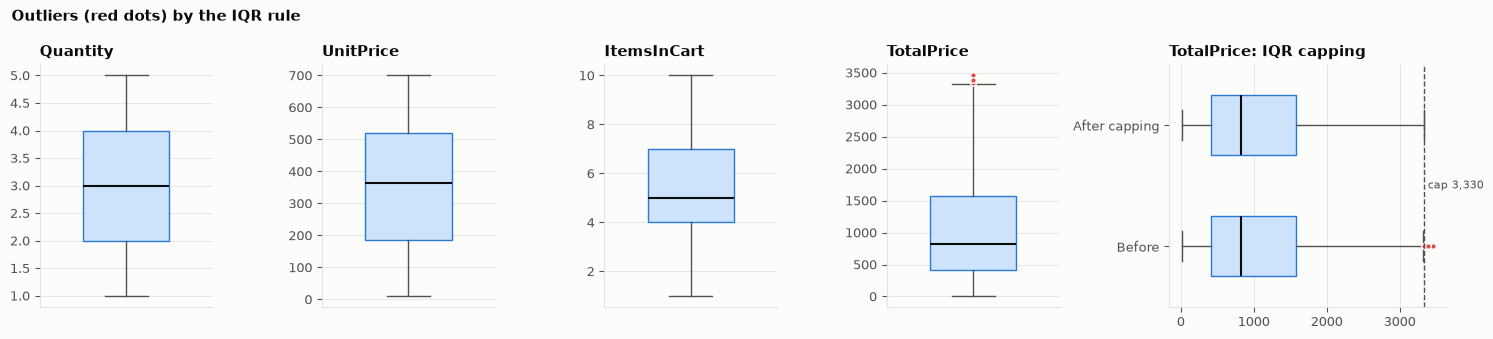

TotalPrice max before: 3,456.40 | after: 3,330.41 | largest change: 3.6%
Rows before: 1200 | rows after: 1200


In [21]:
fig = report.plot_outliers(raw, model, pipe.outlier_bounds_)
plt.show()
before, after = raw["TotalPrice"].max(), model["TotalPrice"].max()
print(f"TotalPrice max before: {before:,.2f} | after: {after:,.2f} "
      f"| largest change: {(before - after) / before * 100:.1f}%")
print("Rows before:", len(raw), "| rows after:", len(model))

## 9. Phase 2 — Engineered features

Seven new features, all computed with vectorised pandas operations (no row loops):

| Feature | Meaning | Why it can help |
|---|---|---|
| `OrderMonth` | 1–12 | seasonality (e.g. winter offers) |
| `OrderDayOfWeek` | 0 = Mon … 6 = Sun | weekly buying patterns |
| `IsWeekend` | 1 on Sat/Sun | weekend vs weekday behaviour |
| `DaysSinceStart` | days since the first order | long-term trend |
| `HasCoupon` | 1 if any coupon was used | discount effect |
| `OtherItemsInCart` | ItemsInCart − Quantity | size of the rest of the basket |
| `QuantityShareOfCart` | Quantity ÷ ItemsInCart | how dominant this product is in the basket |

In [22]:
new_features = ["OrderMonth", "OrderDayOfWeek", "IsWeekend", "DaysSinceStart",
                "HasCoupon", "OtherItemsInCart", "QuantityShareOfCart"]
analysis[["OrderID", "Date", "Quantity", "ItemsInCart", "CouponCode"] + new_features].head()

,OrderID,Date,Quantity,ItemsInCart,CouponCode,OrderMonth,OrderDayOfWeek,IsWeekend,DaysSinceStart,HasCoupon,OtherItemsInCart,QuantityShareOfCart
0,ORD200000,2023-01-04,5,7,SAVE10,1,2,0,3,1,2,0.714286
1,ORD200001,2024-08-23,2,3,SAVE10,8,4,0,600,1,1,0.666667
2,ORD200002,2024-02-27,5,8,FREESHIP,2,1,0,422,1,3,0.625000
3,ORD200003,2023-10-15,1,5,SAVE10,10,6,1,287,1,4,0.200000
4,ORD200004,2025-05-08,4,8,SAVE10,5,3,0,858,1,4,0.500000


### 9.1 Summary statistics of the new features

In [23]:
analysis[new_features].describe().T.round(3)

,count,mean,std,min,25%,50%,75%,max
OrderMonth,1200.0,5.995,3.344,1.000,3.00,6.0,9.00,12.0
OrderDayOfWeek,1200.0,3.051,2.026,0.000,1.00,3.0,5.00,6.0
IsWeekend,1200.0,0.298,0.458,0.000,0.00,0.0,1.00,1.0
DaysSinceStart,1200.0,446.708,265.870,0.000,214.75,447.0,677.50,911.0
HasCoupon,1200.0,0.742,0.437,0.000,0.00,1.0,1.00,1.0
OtherItemsInCart,1200.0,2.539,1.736,0.000,1.00,3.0,4.00,5.0
QuantityShareOfCart,1200.0,0.580,0.250,0.167,0.40,0.5,0.75,1.0


## 10. Phase 2 — One-hot encoding

Machine-learning models need numbers, not text. Each text column becomes 0/1 columns.
One category per column is dropped as the **reference** (the most frequent one) to avoid the
dummy-variable trap, where the dummies of a column always add up to 1.

In [24]:
encoding = pd.DataFrame({
    "categories": {c: len(v) for c, v in pipe.categories_.items()},
    "reference (dropped)": pipe.reference_category_,
})
encoding["new columns"] = encoding["categories"] - 1
encoding

,categories,reference (dropped),new columns
Product,7,Printer,6
PaymentMethod,5,Online,4
OrderStatus,5,Cancelled,4
CouponCode,4,FREESHIP,3
ReferralSource,5,Instagram,4


### 10.1 Example: `PaymentMethod` after encoding

`Online` is the reference, so an Online order has 0 in all four columns.

In [25]:
model.filter(like="PaymentMethod_").head()

,PaymentMethod_Cash,PaymentMethod_Credit_Card,PaymentMethod_Debit_Card,PaymentMethod_Gift_Card
0,0,0,1,0
1,0,0,0,0
2,0,1,0,0
3,0,0,1,0
4,0,0,0,0


## 11. Phase 2 — Collinearity removal

Two features that move together (|r| > 0.80) carry the same information. Keeping both makes
linear models unstable. Algorithm: correlation matrix → upper triangle → pairs above 0.80 → drop one.

This dataset has **no target column**, so the rule "keep the one closer to the target" cannot be
used. Instead, the feature with the higher **average correlation to all other features**
(the more redundant one) is dropped.

In [26]:
pipe.collinearity_table_

,feature_a,feature_b,abs_corr,a_avg_corr,b_avg_corr,dropped
0,HasCoupon,CouponCode_NONE,1.0000,0.0735,0.0735,CouponCode_NONE
1,OtherItemsInCart,QuantityShareOfCart,0.8381,0.0712,0.0773,QuantityShareOfCart


- `CouponCode_NONE` is an exact mirror of `HasCoupon` (r = 1.0), so it is dropped.
  `HasCoupon` together with `CouponCode_SAVE10` and `CouponCode_WINTER15` still identifies all
  four coupon groups.
- `QuantityShareOfCart` and `OtherItemsInCart` describe the same basket (r ≈ 0.84);
  `QuantityShareOfCart` is the more redundant one and is dropped.

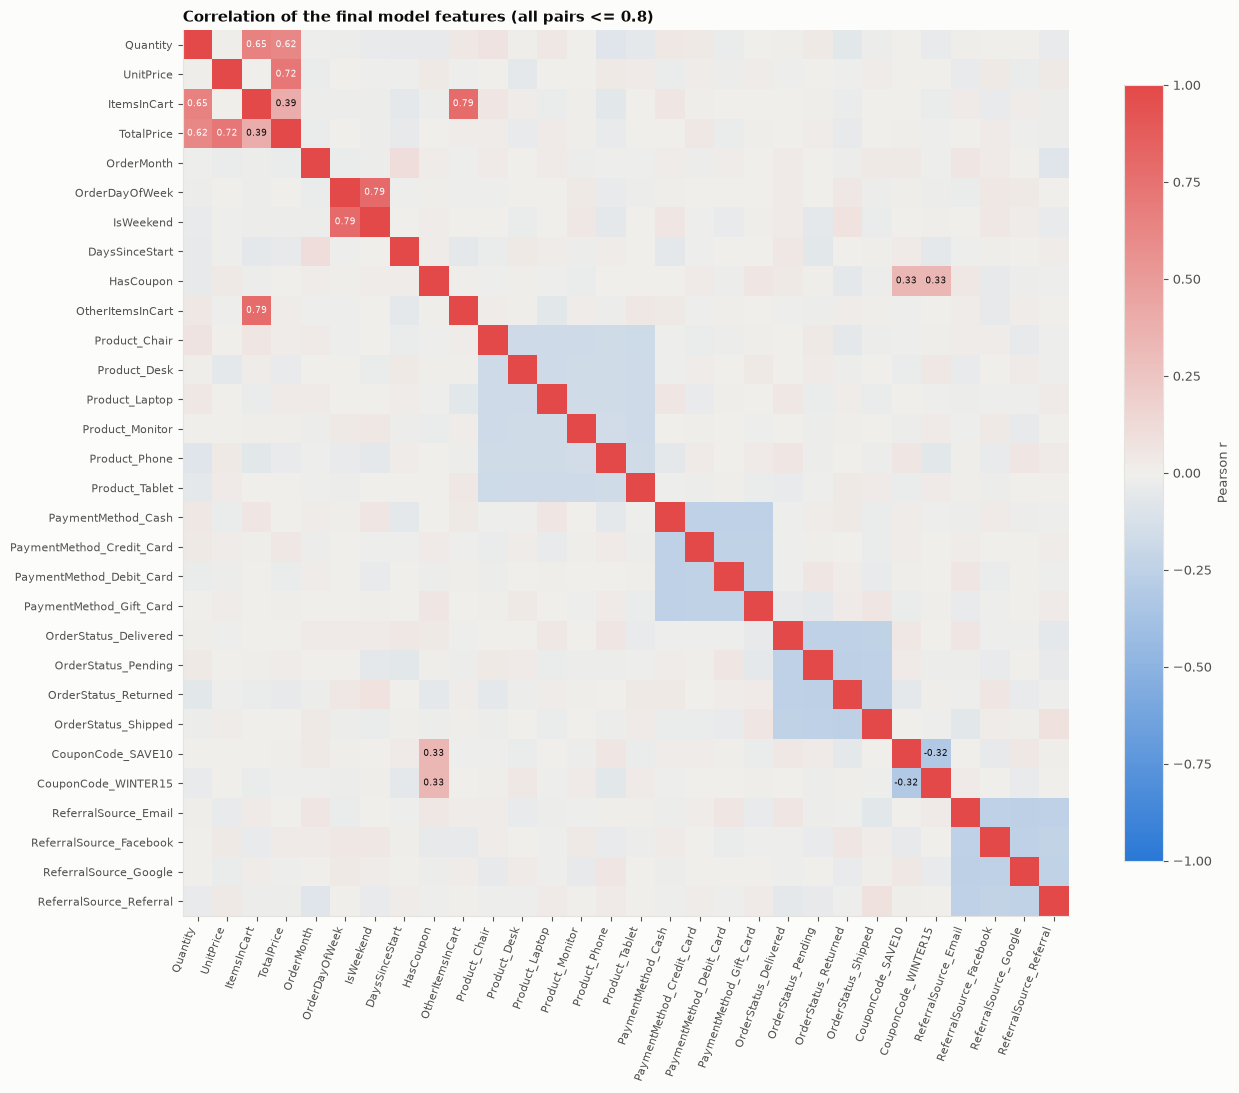

Highest remaining |r| between two features: 0.795


In [27]:
fig = report.plot_correlation(model)
plt.show()
corr = model.drop(columns=config.ID_COLUMN).corr().abs().to_numpy(copy=True)
np.fill_diagonal(corr, 0)
print("Highest remaining |r| between two features:", round(corr.max(), 3))

## 12. Phase 3 — Data contracts and consistency

The output table was validated inside the pipeline by a Pandera schema
(no nulls, 0/1 flags, `TotalPrice` within the cap, `QuantityShareOfCart` in (0, 1], …).
Below, three final checks:

1. No missing values anywhere.
2. Every model feature is numeric.
3. **No training-serving skew:** running the fitted pipeline again with `transform()`
   gives exactly the same output.

In [28]:
analysis_2, model_2 = pipe.transform(raw)
final_checks = {
    "missing values (analysis)": int(analysis.isna().sum().sum()),
    "missing values (model)": int(model.isna().sum().sum()),
    "non-numeric model features": sum(not pd.api.types.is_numeric_dtype(model[c]) for c in pipe.feature_columns_),
    "transform() identical to fit_transform()": bool(model_2.equals(model) and analysis_2.equals(analysis)),
}
pd.Series(final_checks, name="result").to_frame()

INFO | TotalPrice capped to [-1341.41, 3330.41]: 0 low, 8 high
INFO | Pipeline done: 1200 rows in, 1200 rows out, 30 model features.


,result
missing values (analysis),0
missing values (model),0
non-numeric model features,0
transform() identical to fit_transform(),True


## 13. Save outputs

The same files are produced by `python main.py`.

In [29]:
config.PROCESSED_DIR.mkdir(parents=True, exist_ok=True)
analysis.to_csv(config.PROCESSED_DIR / "orders_clean.csv", index=False)
model.to_csv(config.PROCESSED_DIR / "orders_model_ready.csv", index=False)
model.to_parquet(config.PROCESSED_DIR / "orders_model_ready.parquet", index=False)
pipe.save_params(config.ARTIFACTS_DIR / "pipeline_params.json")
for p in sorted(config.PROCESSED_DIR.glob("*")) + [config.ARTIFACTS_DIR / "pipeline_params.json"]:
    print(f"{p.relative_to(ROOT).as_posix():45s} {p.stat().st_size / 1024:7.1f} KB")

data/processed/orders_clean.csv                 122.8 KB
data/processed/orders_model_ready.csv            98.2 KB
data/processed/orders_model_ready.parquet        52.7 KB
artifacts/pipeline_params.json                    4.2 KB


## 14. Summary

In [30]:
summary = {
    "raw rows x columns": f"{raw.shape[0]} x {raw.shape[1]}",
    "analysis table": f"{analysis.shape[0]} x {analysis.shape[1]}",
    "model table": f"{model.shape[0]} x {model.shape[1]} (OrderID + {len(pipe.feature_columns_)} features)",
    "rows dropped": pipe.rows_dropped_,
    "missing values fixed": int(raw.isna().sum().sum()),
    "TotalPrice values capped": pipe.outlier_counts_["TotalPrice"]["above"],
    "engineered features (kept in model)": sum(f in pipe.feature_columns_ for f in new_features),
    "collinear features removed": ", ".join(pipe.collinear_dropped_),
}
pd.Series(summary, name="value").to_frame()

,value
raw rows x columns,1200 x 14
analysis table,1200 x 18
model table,1200 x 31 (OrderID + 30 features)
rows dropped,0
missing values fixed,309
TotalPrice values capped,8
engineered features (kept in model),6
collinear features removed,"CouponCode_NONE, QuantityShareOfCart"


**Project requirements — status**

| Requirement | Done |
|---|---|
| Handle missing data with statistical imputation (Mean / Median / KNN) | `CouponCode` structural fill; Mean vs Median vs KNN measured on hidden values; KNN path built into the pipeline |
| Identify and neutralise outliers (Z-score / IQR) | both rules applied; 8 `TotalPrice` values capped with `numpy.clip` |
| At least 3 new features | 7 engineered, 6 kept after collinearity removal |
| Pandas, NumPy, statistical analysis | fully vectorised pipeline |

